# Bi 2021 — Kidney RCC · 02 manifold
Fit the cell-state geometry. The malignant embedding is a single low-aspect mass with no Y-shape; a PPT *tree* forces branch nodes onto it (metric over embedding — the attempt-3/5 failure mode), so the topology is fit with a scFates **curve** (non-branching), fold-checked, rooted at the Gast/pSom-high developmental origin.

In [1]:
import os, sys, glob, io, contextlib
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
import scipy.sparse as sp
from scipy.sparse.csgraph import shortest_path
from numpy.linalg import svd
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
name = os.path.basename(os.getcwd())
cat  = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*6))
pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)

manifold: 7822 cells on the joint embedding (full component)
UMAP aspect ratio (major/minor std) = 1.70  (~1 blob, not an elongated strip)


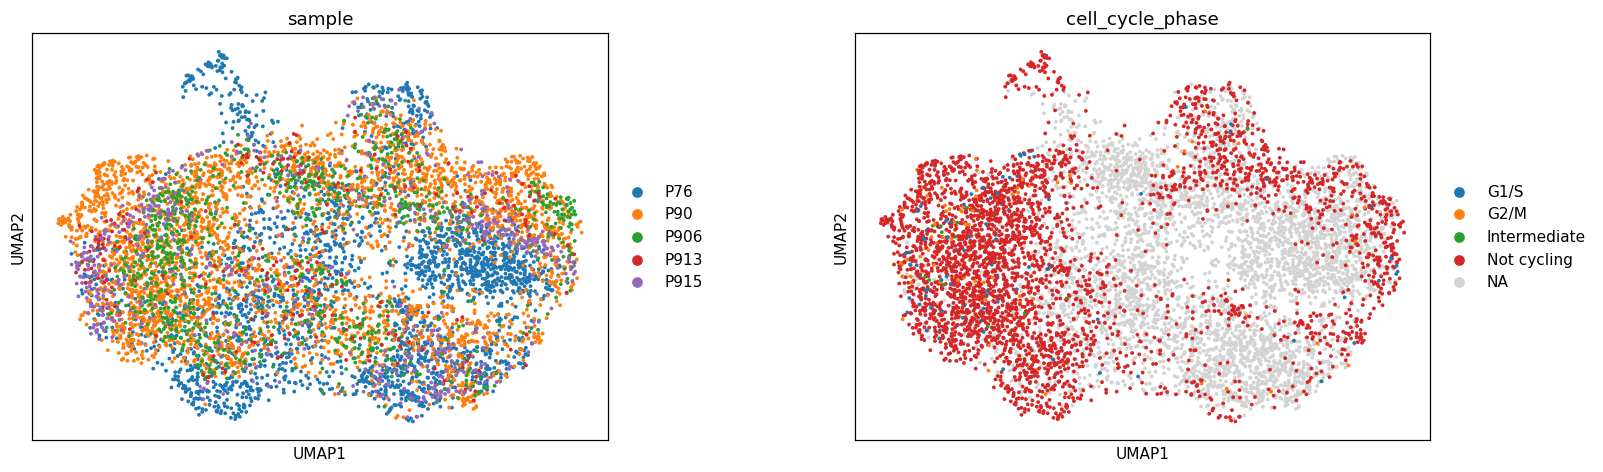

In [3]:
adata = sc.read_h5ad(os.path.join(pth_out, 'processed.h5ad'))
sub = adata.copy()
print('manifold:', sub.shape[0], 'cells on the joint embedding (full component)')
xy = sub.obsm['X_umap']; c = xy - xy.mean(0); u,s,vt = svd(c, full_matrices=False)
print(f'UMAP aspect ratio (major/minor std) = {s[0]/s[1]:.2f}  (~1 blob, not an elongated strip)')
sc.pl.umap(sub, color=['sample','cell_cycle_phase'], size=25, wspace=.3)

### Topology: curve, not tree
A PPT tree probe returns fork nodes, but they are the metric branching a 2-D cloud, not arms in the embedding. The curve is accepted only if it is **fork-free and fold-free** (min non-adjacent node self-approach > 1 median edge).

In [4]:
def fold_diag(ad):
    B = np.asarray(ad.uns['graph']['B']); F = ad.uns['graph']['F'].T
    G = shortest_path(sp.csr_matrix((B>0).astype(int)), unweighted=True)
    ii,jj = np.where(np.triu(B>0)); med_edge = np.median(np.sqrt(((F[ii]-F[jj])**2).sum(1)))
    dmin = np.inf
    for a in range(F.shape[0]):
        for b in range(a+1, F.shape[0]):
            if G[a,b] >= 3: dmin = min(dmin, np.sqrt(((F[a]-F[b])**2).sum()))
    tips = int(((B>0).sum(0)==1).sum()); forks = int(((B>0).sum(0)>=3).sum())
    return dmin/med_edge, tips, forks
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.curve(sub, Nodes=20, use_rep='X_umap', epg_lambda=0.3, epg_mu=100.0, seed=SEED, plot=False)
sa, tips, forks = fold_diag(sub)
print(f'curve: {tips} tips, {forks} forks | fold self-approach ratio = {sa:.2f} (>1 = fold-free)')
assert forks == 0 and sa > 1, 'topology check failed'

curve: 2 tips, 0 forks | fold self-approach ratio = 2.99 (>1 = fold-free)


### Score embryonic modules and graph-smooth for geography

In [5]:
pth_feat = os.path.join(pth_data, 'features', 'biomart')
feat = {os.path.basename(fn).replace('.csv',''): pd.read_csv(fn).hsapiens.dropna().drop_duplicates()
        for fn in sorted(glob.glob(os.path.join(pth_feat,'*.csv')))}
g_ref = feat['union'].loc[feat['union'].isin(sub.var_names)]
label = {'GSE162534':'Gast','GSE229103':'pSom','rRNAModifications':'Crest'}
for src,lab in label.items():
    g = feat[src].loc[feat[src].isin(sub.var_names)]
    sc.tl.score_genes(sub, gene_list=g, score_name=lab, ctrl_as_ref=False,
                      gene_pool=g_ref, random_state=1234)
    print(f'{lab}: {g.size}/{feat[src].size} genes present')
A = (sub.obsp['connectivities']>0).astype(float); A = A + sp.eye(A.shape[0])
A = sp.diags(1/np.array(A.sum(1)).ravel()) @ A
S = sub.obs[['Gast','pSom','Crest']].values.copy()
for _ in range(3): S = A @ S
for j,lab in enumerate(['Gast','pSom','Crest']): sub.obs[lab+'_sm'] = S[:,j]

Gast: 72/81 genes present
pSom: 83/98 genes present
Crest: 96/104 genes present


### Root at the Gast/pSom-high, Crest-low tip; infer pseudotime
Neural crest is developmentally *late*, so the root belongs at the Gast/pSom pole (Kürten root lesson). The root is derived — the tip maximising `Gast+pSom−Crest` on cells within 3 graph steps — never a proliferation state.

In [6]:
B = np.asarray(sub.uns['graph']['B']); tps = np.where((B>0).sum(0)==1)[0]
R = np.asarray(sub.obsm['X_R']); hard = R.argmax(1)
D = shortest_path(sp.csr_matrix((B>0).astype(int)), unweighted=True)
info = {}
for t in tps:
    m = np.isin(hard, np.where(D[t]<=3)[0])
    info[t] = (sub.obs['Gast_sm'][m].mean(), sub.obs['pSom_sm'][m].mean(), sub.obs['Crest_sm'][m].mean())
    print(f'tip {t}: Gast={info[t][0]:+.4f} pSom={info[t][1]:+.4f} Crest={info[t][2]:+.4f}')
root = int(max(tps, key=lambda t: info[t][0]+info[t][1]-info[t][2]))
print('derived root = tip', root, '(Gast/pSom-high, Crest-low)')
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.root(sub, root); scf.tl.pseudotime(sub, n_map=1, seed=SEED)
t = sub.obs['t'].values
print('gradient along pseudotime (Spearman rho on smoothed):')
for sname in ['Gast_sm','pSom_sm','Crest_sm']:
    rho,p = spearmanr(t, sub.obs[sname]); print(f'  {sname}: rho={rho:+.3f} p={p:.1e}')

tip 0: Gast=-0.0115 pSom=+0.0337 Crest=-0.0385
tip 2: Gast=-0.0126 pSom=+0.0241 Crest=-0.0214
derived root = tip 0 (Gast/pSom-high, Crest-low)
gradient along pseudotime (Spearman rho on smoothed):
  Gast_sm: rho=-0.156 p=7.8e-44
  pSom_sm: rho=-0.463 p=0.0e+00
  Crest_sm: rho=+0.711 p=0.0e+00


### Fold check — draw the fitted curve edges over pseudotime

single monotone arc, no self-crossing -> fold-free (matches self-approach ratio)


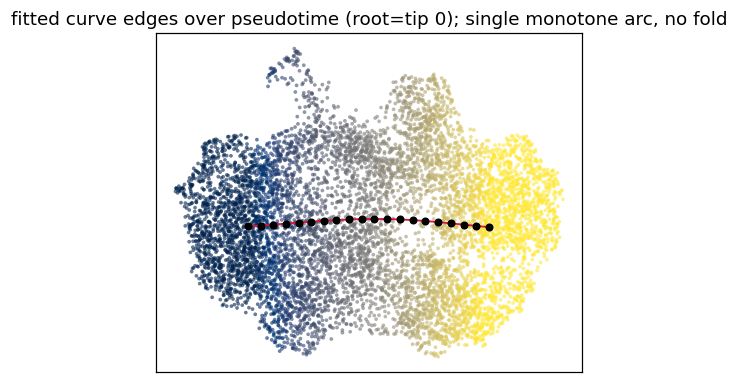

In [7]:
F = sub.uns['graph']['F'].T; Bc = np.asarray(sub.uns['graph']['B'])
fig, ax = plt.subplots(figsize=(5,4))
ax.scatter(sub.obsm['X_umap'][:,0], sub.obsm['X_umap'][:,1], s=6, c=sub.obs['t'], cmap='cividis', alpha=.6, lw=0)
ii,jj = np.where(np.triu(Bc>0))
for a,b in zip(ii,jj): ax.plot([F[a,0],F[b,0]],[F[a,1],F[b,1]], '-', color='crimson', lw=1.2)
ax.scatter(F[:,0],F[:,1], s=18, c='k', zorder=5)
ax.set_title(f'fitted curve edges over pseudotime (root=tip {root}); single monotone arc, no fold')
ax.set_xticks([]); ax.set_yticks([])
print('single monotone arc, no self-crossing -> fold-free (matches self-approach ratio)')

### Orient the linear layout: low pseudotime on the left

In [8]:
xy = sub.obsm['X_umap'].copy(); t = sub.obs['t'].values
sx = 1.0 if np.corrcoef(xy[:,0], t)[0,1] > 0 else -1.0
xyr = np.column_stack([sx*xy[:,0], xy[:,1]])
r = float(np.corrcoef(xyr[:,0], t)[0,1])
assert r > 0, f'orientation derivation failed (corr={r:+.2f})'
sub.obsm['X_umap_lin'] = xyr; sub.uns['orient_sx'] = sx
print(f'orientation: X_umap_lin = ({sx:+.0f}*raw_x, raw_y) [derived sign]; '
      f'corr(x_lin, pseudotime) = {r:+.2f} (low pt on left)')

orientation: X_umap_lin = (+1*raw_x, raw_y) [derived sign]; corr(x_lin, pseudotime) = +0.99 (low pt on left)


In [9]:
if 'epg' in sub.uns:
    sub.uns['epg'] = {'NodePositions': np.asarray(sub.uns['epg']['NodePositions'])}
sub.write(os.path.join(pth_out, 'manifold.h5ad'))
print('saved manifold.h5ad', sub.shape)

saved manifold.h5ad (7822, 25001)


### Deliverable — `manifold.pdf` (pseudotime on the house linear layout)

saved manifold.pdf | cells: 7822


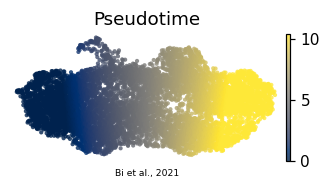

In [10]:
xl = sub.obsm['X_umap_lin']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
plot = sub.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(plot, color='t', cmap='cividis', size=30, alpha=.8, colorbar_loc='right',
           frameon=False, show=False, ax=ax, title='Pseudotime')
ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
ax.text(.5,-.12,'Bi et al., 2021', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'manifold.pdf'), bbox_inches='tight')
print('saved manifold.pdf | cells:', sub.n_obs)